In [1]:
import sys
sys.path.append("src/")


# ── Logging setup ─────────────────────────────────────────────────────────────
import logging

logging.basicConfig(
    level   = logging.INFO,
    format  = "%(asctime)s | %(levelname)s | %(message)s",
    datefmt = "%H:%M:%S",
)
log = logging.getLogger(__name__)

log.info("Logging initialized.")

13:40:59 | INFO | Logging initialized.


# Splits Generation

In [2]:
import config
from splits import generate_all_splits

splits = generate_all_splits(config)

# splits["random"]      → DataFrame with all tracks, split column = train/val/test
# splits["udio_train"]  → train on Udio, test on Suno
# splits["suno_train"]  → train on Suno, test on Udio

13:41:00 | INFO | Loading metadata...
13:41:00 | INFO | Loaded 6544 tracks from /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/music_data/metadata_usable.csv
13:41:00 | INFO | 
Source distribution:
13:41:00 | INFO | label  source_name
ai     Suno            182
       Udio           4872
human  FMA            1490
13:41:00 | INFO | Building random stratified split...
13:41:00 | INFO | 
13:41:00 | INFO | Split summary: random
13:41:00 | INFO | =======================================================
13:41:00 | INFO | 
split label source_name  tracks
 test    ai        Suno      27
 test    ai        Udio     731
 test human         FMA     224
train    ai        Suno     127
train    ai        Udio    3410
train human         FMA    1043
  val    ai        Suno      28
  val    ai        Udio     731
  val human         FMA     223
13:41:00 | INFO | 
Totals per split:
split
test      982
train    4580
val       982
13:41:00 | INFO | Saved split → /Users/macbookpro/Documents

# Chunk Sampling

In [3]:
# ── Section 2: Chunk Sampling ─────────────────────────────────────────────────
from sampling import build_chunk_index, cap_ai_chunks

# Build chunk index for whichever split strategy
split_df  = splits[config.SPLIT_STRATEGY]   # e.g. splits["random"]

chunk_df  = build_chunk_index(
    split_df    = split_df,
    config      = config,
    output_path = config.CHUNKS_DIR / f"{config.SPLIT_STRATEGY}_chunks_raw.csv",
)

# Cap AI chunks in training split to match human count
chunk_df_balanced = cap_ai_chunks(
    chunk_df = chunk_df,
    config   = config,
    split    = "train",
)

chunk_df_balanced.to_csv(
    config.CHUNKS_DIR / f"{config.SPLIT_STRATEGY}_chunks_balanced.csv",
    index=False,
)

# Quick sanity check
train = chunk_df_balanced[chunk_df_balanced["split"] == "train"]
print(train.groupby(["label", "source_name"]).size())

13:41:00 | INFO | Building chunk index for 6544 tracks...
13:41:01 | INFO | 
13:41:01 | INFO | Chunk index summary
13:41:01 | INFO | =======================================================
13:41:01 | INFO | 
split label source_name  chunks
 test    ai        Suno     135
 test    ai        Udio    3187
 test human         FMA    2605
train    ai        Suno     630
train    ai        Udio   14830
train human         FMA   12055
  val    ai        Suno     140
  val    ai        Udio    3166
  val human         FMA    2591
13:41:01 | INFO | 
Total chunks : 39339
13:41:01 | INFO | Unique tracks: 6544
13:41:01 | INFO | Chunks/track : mean=6.0 min=2 max=12
13:41:01 | INFO | Saved chunk index → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/data/chunks/random_chunks_raw.csv
13:41:01 | INFO | [cap_ai_chunks] split='train' | human=12055 | ai=15460
13:41:01 | INFO |   Udio: 14830 → 11564 chunks kept
13:41:01 | INFO |   Suno: 630 → 491 chunks kept
13:41:01 | INFO | After capping: 

label  source_name
ai     Suno             491
       Udio           11564
human  FMA            12055
dtype: int64


# MERT Mining

In [4]:
# ── Section 3: Hard-Negative Mining ──────────────────────────────────────────
import torch
from mert_mining import run_hard_negative_mining

with open('tokens/token_hf.txt', 'r') as file:
    token = file.read()

from huggingface_hub import login

# Use this to pass the token directly
login(token=token)


device = (torch.device("mps")  if torch.backends.mps.is_available() else
          torch.device("cuda") if torch.cuda.is_available() else
          torch.device("cpu"))
print(f"Device: {device}")

if config.USE_HARD_NEGATIVES:
    chunk_df_final = run_hard_negative_mining(
        chunk_df              = chunk_df_balanced,
        config                = config,
        device                = device,
        # Cache embeddings so you don't re-extract if you rerun the cell
        embeddings_cache_path = (config.CHUNKS_DIR /
                                 f"{config.SPLIT_STRATEGY}_train_embeddings.npy"),
    )
else:
    log.info("USE_HARD_NEGATIVES=False — skipping mining, "
             "using balanced chunk index as-is.")
    chunk_df_final = chunk_df_balanced

# Save final chunk index
final_path = config.CHUNKS_DIR / f"{config.SPLIT_STRATEGY}_chunks_final.csv"
chunk_df_final.to_csv(final_path, index=False)
print(f"Final chunk index saved → {final_path}")
print(chunk_df_final.groupby(
    ["split", "label", "source_name"]
).size().rename("chunks"))

13:41:02 | INFO | HTTP Request: GET https://huggingface.co/api/whoami-v2 "HTTP/1.1 200 OK"
13:41:03 | INFO | USE_HARD_NEGATIVES=False — skipping mining, using balanced chunk index as-is.


Device: mps
Final chunk index saved → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/data/chunks/random_chunks_final.csv
split  label  source_name
test   ai     Suno             135
              Udio            3187
       human  FMA             2605
train  ai     Suno             491
              Udio           11564
       human  FMA            12055
val    ai     Suno             140
              Udio            3166
       human  FMA             2591
Name: chunks, dtype: int64


# Spectrogram Generation

In [5]:
# ── Section 4: Spectrogram Generation ────────────────────────────────────────
from spectrogram import generate_spectrograms, load_manifest

# Generate spectrograms for all chunks (train + val + test)
# This is the most time-consuming step — runs once, then use load_manifest
# manifest = generate_spectrograms(
#     chunk_df   = chunk_df_final,
#     config     = config,
#     output_dir = config.SPECTROGRAMS_DIR / config.SPLIT_STRATEGY,
# )

# ── On subsequent runs — skip generation and just reload ──────────────────────
# Uncomment the above to regenerate if the manifest is corrupted
manifest, spec_mean, spec_std = load_manifest(
    config.SPECTROGRAMS_DIR / config.SPLIT_STRATEGY
)

# Quick sanity check — load one spectrogram and verify shape
import numpy as np
sample_path = manifest.iloc[0]["npy_path"]
sample_spec = np.load(sample_path)
print(f"Spectrogram shape : {sample_spec.shape}")     # should be (128, 431)
print(f"dtype             : {sample_spec.dtype}")     # float32
print(f"value range       : [{sample_spec.min():.3f}, {sample_spec.max():.3f}]")
print(f"\nManifest columns  : {list(manifest.columns)}")
print(f"\nChunk counts:")
print(manifest.groupby(["split", "label", "source_name"]).size()
      .rename("chunks").to_string())

13:41:03 | INFO | Loaded manifest: 35934 chunks
13:41:03 | INFO | Norm stats: mean=-13.366174, std=14.409119


Spectrogram shape : (128, 431)
dtype             : float32
value range       : [-1.603, 2.780]

Manifest columns  : ['chunk_id', 'file_path', 'start_sec', 'end_sec', 'label', 'source_name', 'split', 'track_id', 'npy_path', 'spec_mean', 'spec_std']

Chunk counts:
split  label  source_name
test   ai     Suno             135
              Udio            3187
       human  FMA             2605
train  ai     Suno             491
              Udio           11564
       human  FMA            12055
val    ai     Suno             140
              Udio            3166
       human  FMA             2591


# Build Data Loaders

In [6]:
from dataset import build_dataloaders

# For CNN baseline
loaders = build_dataloaders(
    manifest   = manifest,
    config     = config,
    model_type = "cnn",      # override config if needed
)

# Quick sanity check — inspect one batch
batch_inputs, batch_labels, batch_metas = next(iter(loaders["train"]))
print(f"Input shape  : {batch_inputs.shape}")   # (64, 1, 128, 431)
print(f"Labels shape : {batch_labels.shape}")   # (64,)
print(f"Label balance: "
      f"{(batch_labels==0).sum().item()} human / "
      f"{(batch_labels==1).sum().item()} AI")
print(f"Sources      : "
      f"{set(m['source_name'] for m in batch_metas)}")
print(f"\nSwitching to CNN+LSTM:")

# Switching to CNN+LSTM — same manifest, different dataset class
loaders_seq = build_dataloaders(
    manifest   = manifest,
    config     = config,
    model_type = "cnn_lstm",
)
seq_inputs, seq_labels, _ = next(iter(loaders_seq["train"]))
print(f"Sequence input shape: {seq_inputs.shape}")
# (64, n_segments, 1, n_mels, segment_frames) e.g. (64, 10, 1, 128, 43)

13:41:03 | INFO | 
Building DataLoaders — model_type='cnn'
13:41:03 | INFO | [MelSpecDataset] split=train | augment=True | 24110 chunks | human=12055 | ai=12055
13:41:03 | INFO |   WeightedSampler: human_weight=1.000, ai_weight=1.000
13:41:03 | INFO |   train loader: 24110 chunks | 376 batches | batch_size=64
13:41:03 | INFO | [MelSpecDataset] split=val | augment=False | 5897 chunks | human=2591 | ai=3306
13:41:03 | INFO |   val   loader: 5897 chunks | 93 batches | batch_size=64
13:41:03 | INFO | [MelSpecDataset] split=test | augment=False | 5927 chunks | human=2605 | ai=3322
13:41:03 | INFO |   test  loader: 5927 chunks | 93 batches | batch_size=64
13:41:03 | INFO | 
Building DataLoaders — model_type='cnn_lstm'
13:41:03 | INFO | [MelSpecSeqDataset] split=train | augment=True | 24110 chunks | human=12055 | ai=12055
13:41:03 | INFO |   Sequence mode: 10 segments × 43 frames each
13:41:03 | INFO |   WeightedSampler: human_weight=1.000, ai_weight=1.000
13:41:03 | INFO |   train loader: 24

Input shape  : torch.Size([64, 1, 128, 431])
Labels shape : torch.Size([64])
Label balance: 30 human / 34 AI
Sources      : {'Suno', 'Udio', 'FMA'}

Switching to CNN+LSTM:
Sequence input shape: torch.Size([64, 10, 1, 128, 43])


# Model architectures for AI music detection

All models share a common CNN backbone that encodes a mel spectrogram (or one segment of it) into a feature vector. Three heads are available:

- CNNClassifier     — CNN backbone + global pooling + MLP head
- -                   Input : (B, 1, n_mels, time_frames)
- -                   Output: (B, 2)

- CNNRNNClassifier  — CNN backbone (per segment) + RNN + MLP head
- -                    Input : (B, n_segments, 1, n_mels, segment_frames)
- -                    Output: (B, 2)
- -                    rnn_type: "lstm" | "gru"

- Factory function:
- -   build_model(config) — returns the right model based on config.MODEL_TYPE

- Design principles:
-   - Batch normalisation after every conv block for training stability
-   - Dropout before the classifier head
-   - All hyperparameters (channels, dropout, rnn size) come from config
-   - Models print a parameter count summary on construction

In [7]:
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# import logging

# log = logging.getLogger(__name__)


# # ── CNN Backbone ──────────────────────────────────────────────────────────────

# class ConvBlock(nn.Module):
#     """
#     Single conv block: Conv2d → BatchNorm → ReLU → MaxPool.
#     Used as the repeating unit of the CNN backbone.
#     """

#     def __init__(
#         self,
#         in_channels: int,
#         out_channels: int,
#         kernel_size: int = 3,
#         pool_size: tuple  = (2, 2),
#     ):
#         super().__init__()
#         self.block = nn.Sequential(
#             nn.Conv2d(
#                 in_channels,
#                 out_channels,
#                 kernel_size = kernel_size,
#                 padding     = kernel_size // 2,
#                 bias        = False,        # bias redundant with BN
#             ),
#             nn.BatchNorm2d(out_channels),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(pool_size),
#         )

#     def forward(self, x: torch.Tensor) -> torch.Tensor:
#         return self.block(x)


# class CNNBackbone(nn.Module):
#     """
#     Stacked ConvBlocks that encode a (1, n_mels, time_frames) spectrogram
#     into a (channels[-1], h', w') feature map.

#     Parameters
#     ----------
#     channels : list of output channel counts per block
#                e.g. [32, 64, 128, 256] → 4 conv blocks
#     """

#     def __init__(self, channels: list[int]):
#         super().__init__()
#         in_ch  = 1
#         blocks = []
#         for out_ch in channels:
#             blocks.append(ConvBlock(in_ch, out_ch))
#             in_ch = out_ch
#         self.blocks   = nn.Sequential(*blocks)
#         self.out_channels = channels[-1]

#     def forward(self, x: torch.Tensor) -> torch.Tensor:
#         return self.blocks(x)




# # ── Utilities ─────────────────────────────────────────────────────────────────

# def _log_model_summary(model: nn.Module, name: str) -> None:
#     """Log parameter count breakdown."""
#     total     = sum(p.numel() for p in model.parameters())
#     trainable = sum(p.numel() for p in model.parameters()
#                     if p.requires_grad)
#     log.info(f"\n{'='*55}")
#     log.info(f"Model: {name}")
#     log.info(f"  Total parameters     : {total:,}")
#     log.info(f"  Trainable parameters : {trainable:,}")
#     log.info(f"{'='*55}")


# def get_model_input_shape(config, model_type: str | None = None) -> tuple:
#     """
#     Return the expected input shape for a given model type.
#     Useful for verifying DataLoader output before training.

#     Returns
#     -------
#     Tuple describing one sample shape (without batch dimension).
#     """
#     mtype = (model_type or config.MODEL_TYPE).lower()
#     if mtype == "cnn":
#         return (1, config.N_MELS, config.SPEC_TIME_FRAMES)
#     elif mtype in ("cnn_lstm", "cnn_gru"):
#         segment_frames = 43
#         n_segments     = config.SPEC_TIME_FRAMES // segment_frames
#         return (n_segments, 1, config.N_MELS, segment_frames)
#     elif mtype == "ast":
#         return (1, config.CHUNK_SEC * 16000)
#     else:
#         raise ValueError(f"Unknown model_type='{mtype}'")

## Basic CNN

In [8]:
# # ── CNN Classifier ────────────────────────────────────────────────────────────

# class CNNClassifier(nn.Module):
#     """
#     CNN backbone + adaptive global average pooling + MLP head.

#     Input  : (B, 1, n_mels, time_frames)
#     Output : (B, 2)  — raw logits for CrossEntropyLoss
#     """

#     def __init__(self, config):
#         super().__init__()

#         self.backbone = CNNBackbone(config.CNN_CHANNELS)

#         # Global average pooling collapses (H, W) → (1, 1)
#         # so the model works regardless of input spectrogram size
#         self.pool = nn.AdaptiveAvgPool2d((1, 1))

#         self.classifier = nn.Sequential(
#             nn.Flatten(),
#             nn.Dropout(config.CNN_DROPOUT),
#             nn.Linear(config.CNN_CHANNELS[-1], config.CNN_CHANNELS[-1] // 2),
#             nn.ReLU(inplace=True),
#             nn.Dropout(config.CNN_DROPOUT),
#             nn.Linear(config.CNN_CHANNELS[-1] // 2, 2),
#         )

#         _log_model_summary(self, "CNNClassifier")


#     def _init_weights(self):
#         for m in self.modules():
#             if isinstance(m, nn.Conv2d):
#                 nn.init.kaiming_normal_(
#                     m.weight, mode="fan_out", nonlinearity="relu"
#                 )
#                 m.weight.data *= 0.1          # scale down to prevent early saturation
#                 if m.bias is not None:
#                     nn.init.zeros_(m.bias)
#             elif isinstance(m, nn.BatchNorm2d):
#                 nn.init.ones_(m.weight)
#                 nn.init.zeros_(m.bias)
#                 m.running_mean.zero_()
#                 m.running_var.fill_(1.0)
#             elif isinstance(m, nn.Linear):
#                 nn.init.xavier_uniform_(m.weight)
#                 nn.init.zeros_(m.bias)

#         # Zero-initialize final linear layer so model starts at 50/50
#         last_linear = None
#         for m in self.modules():
#             if isinstance(m, nn.Linear):
#                 last_linear = m
#         if last_linear is not None:
#             nn.init.zeros_(last_linear.weight)
#             nn.init.zeros_(last_linear.bias)


#     def forward(self, x: torch.Tensor) -> torch.Tensor:
#         # x : (B, 1, n_mels, time_frames)
#         features = self.backbone(x)     # (B, C, H', W')
#         pooled   = self.pool(features)  # (B, C, 1, 1)
#         logits   = self.classifier(pooled)  # (B, 2)
#         return logits

#     def forward_features(self, x: torch.Tensor) -> torch.Tensor:
#         """
#         Return pooled feature vector before the classifier head.
#         Useful for embedding-space analysis and fine-tuning.
#         """
#         features = self.backbone(x)
#         pooled   = self.pool(features)
#         return pooled.view(pooled.size(0), -1)   # (B, C)

## CNN + RNN

In [9]:
# # ── CNN + RNN Classifier ──────────────────────────────────────────────────────

# class CNNRNNClassifier(nn.Module):
#     """
#     CNN backbone applied per-segment, then RNN over the segment sequence.

#     Input  : (B, n_segments, 1, n_mels, segment_frames)
#     Output : (B, 2)

#     The CNN encodes each segment independently into a feature vector.
#     The RNN (LSTM or GRU) processes the sequence of per-segment features.
#     The final hidden state of the RNN is passed to the classifier head.

#     Parameters
#     ----------
#     rnn_type : "lstm" | "gru"
#     """

#     def __init__(self, config, rnn_type: str = "lstm"):
#         super().__init__()

#         rnn_type = rnn_type.lower()
#         assert rnn_type in ("lstm", "gru"), \
#             f"rnn_type must be 'lstm' or 'gru', got '{rnn_type}'"

#         self.rnn_type = rnn_type
#         self.backbone = CNNBackbone(config.CNN_CHANNELS)

#         # Pool each segment's feature map to a fixed-size vector
#         self.segment_pool = nn.AdaptiveAvgPool2d((1, 1))

#         cnn_out_dim = config.CNN_CHANNELS[-1]

#         RNNClass = nn.LSTM if rnn_type == "lstm" else nn.GRU
#         self.rnn = RNNClass(
#             input_size   = cnn_out_dim,
#             hidden_size  = config.RNN_HIDDEN_SIZE,
#             num_layers   = config.RNN_NUM_LAYERS,
#             batch_first  = True,
#             dropout      = config.RNN_DROPOUT if config.RNN_NUM_LAYERS > 1
#                            else 0.0,
#             bidirectional= False,
#         )

#         self.classifier = nn.Sequential(
#             nn.Dropout(config.CNN_DROPOUT),
#             nn.Linear(config.RNN_HIDDEN_SIZE, config.RNN_HIDDEN_SIZE // 2),
#             nn.ReLU(inplace=True),
#             nn.Dropout(config.CNN_DROPOUT),
#             nn.Linear(config.RNN_HIDDEN_SIZE // 2, 2),
#         )

#         arch_name = f"CNN+{rnn_type.upper()}Classifier"
#         _log_model_summary(self, arch_name)



#     def _init_weights(self):
#         for m in self.modules():
#             if isinstance(m, nn.Conv2d):
#                 nn.init.kaiming_normal_(
#                     m.weight, mode="fan_out", nonlinearity="relu"
#                 )
#                 m.weight.data *= 0.1          # scale down to prevent early saturation
#                 if m.bias is not None:
#                     nn.init.zeros_(m.bias)
#             elif isinstance(m, nn.BatchNorm2d):
#                 nn.init.ones_(m.weight)
#                 nn.init.zeros_(m.bias)
#                 m.running_mean.zero_()
#                 m.running_var.fill_(1.0)
#             elif isinstance(m, nn.Linear):
#                 nn.init.xavier_uniform_(m.weight)
#                 nn.init.zeros_(m.bias)

#         # Zero-initialize final linear layer so model starts at 50/50
#         last_linear = None
#         for m in self.modules():
#             if isinstance(m, nn.Linear):
#                 last_linear = m
#         if last_linear is not None:
#             nn.init.zeros_(last_linear.weight)
#             nn.init.zeros_(last_linear.bias)


#     def forward(self, x: torch.Tensor) -> torch.Tensor:
#         # x : (B, n_segments, 1, n_mels, segment_frames)
#         B, T, C, H, W = x.shape

#         # Encode each segment with CNN
#         # Merge batch and time dims → (B*T, 1, H, W)
#         x_flat   = x.view(B * T, C, H, W)
#         features = self.backbone(x_flat)         # (B*T, C', H', W')
#         pooled   = self.segment_pool(features)   # (B*T, C', 1, 1)
#         pooled   = pooled.view(B, T, -1)         # (B, T, C')

#         # RNN over segment sequence
#         if self.rnn_type == "lstm":
#             rnn_out, (h_n, _) = self.rnn(pooled)
#         else:
#             rnn_out, h_n = self.rnn(pooled)

#         # Use last layer's final hidden state
#         # h_n : (num_layers, B, hidden_size)
#         last_hidden = h_n[-1]                    # (B, hidden_size)

#         logits = self.classifier(last_hidden)    # (B, 2)
#         return logits



# Model Training & Evaluation

In [10]:

# # ── Factory function ──────────────────────────────────────────────────────────

# def build_model(config, model_type: str | None = None) -> nn.Module:
#     """
#     Instantiate the right model based on config.MODEL_TYPE.

#     Parameters
#     ----------
#     config     : config module
#     model_type : override config.MODEL_TYPE if given
#                  options: "cnn" | "cnn_lstm" | "cnn_gru"

#     Returns
#     -------
#     nn.Module ready for training
#     """
#     mtype = (model_type or config.MODEL_TYPE).lower()
#     log.info(f"Building model: {mtype}")

#     if mtype == "cnn":
#         return CNNClassifier(config)
#     elif mtype == "cnn_lstm":
#         return CNNRNNClassifier(config, rnn_type="lstm")
#     elif mtype == "cnn_gru":
#         return CNNRNNClassifier(config, rnn_type="gru")
#     else:
#         raise ValueError(
#             f"Unknown model_type='{mtype}'. "
#             f"Choose from: cnn, cnn_lstm, cnn_gru"
#         )


## Basic CNN

In [11]:
# from models import build_model, get_model_input_shape
# model = build_model(config, model_type="cnn")
# model = model.to(device)

# # Verify input/output shapes with one batch
# expected_shape = get_model_input_shape(config, model_type="cnn")
# print(f"Expected input shape (single sample): {expected_shape}")

# batch_inputs, batch_labels, batch_metas = next(iter(loaders["train"]))
# batch_inputs = batch_inputs.to(device)

# with torch.no_grad():
#     logits = model(batch_inputs)

# print(f"Input  shape : {batch_inputs.shape}")  # (64, 1, 128, 431)
# print(f"Output shape : {logits.shape}")         # (64, 2)
# print(f"Sample logits: {logits[0]}")

In [12]:
from models import build_model
import torch.nn as nn
import torch

model = build_model(config, model_type="cnn").to(device)

# Trace spatial dimensions through the network
x = torch.randn(1, 1, 128, 431).to(device)
with torch.no_grad():
    print("Input        :", x.shape)
    x = model.conv1(x); print("After conv1  :", x.shape)
    x = model.conv2(x); print("After conv2  :", x.shape)
    x = model.conv3(x); print("After conv3  :", x.shape)
    x = model.conv4(x); print("After conv4  :", x.shape)
    x = model.pool(x);  print("After pool   :", x.shape)
    x = x.view(1, -1);  print("After flatten:", x.shape)

# Full forward pass
batch_inputs, batch_labels, _ = next(iter(loaders["train"]))
with torch.no_grad():
    logits = model(batch_inputs.to(device))
    probs  = torch.softmax(logits, dim=1)[:, 1]

print(f"\nOutput shape : {logits.shape}")
print(f"prob mean    : {probs.mean().item():.4f}")
print(f"prob std     : {probs.std().item():.4f}")
print(f"loss         : "
      f"{nn.CrossEntropyLoss()(logits, batch_labels.to(device)).item():.4f}")

13:42:05 | INFO | Building model: cnn
13:42:05 | INFO | 
13:42:05 | INFO | Model: CNNClassifier
13:42:05 | INFO |   Total parameters     : 420,026
13:42:05 | INFO |   Trainable parameters : 420,026
13:42:05 | INFO | =======================================================


Input        : torch.Size([1, 1, 128, 431])
After conv1  : torch.Size([1, 8, 64, 215])
After conv2  : torch.Size([1, 16, 32, 107])
After conv3  : torch.Size([1, 32, 16, 53])
After conv4  : torch.Size([1, 64, 8, 26])
After pool   : torch.Size([1, 64, 4, 2])
After flatten: torch.Size([1, 512])

Output shape : torch.Size([64, 2])
prob mean    : 0.6861
prob std     : 0.2911
loss         : 1.5777


In [13]:
from torch.optim import AdamW
from dataset import build_eval_loader
from sklearn.metrics import roc_auc_score, accuracy_score
import torch.nn as nn
import numpy as np

optimizer_cnn     = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion_cnn     = nn.CrossEntropyLoss()
train_eval_loader = build_eval_loader(manifest, config, "train", "cnn")

for epoch in range(1, 6):
    # ── Train ──────────────────────────────────────────────────────────────
    model.train()
    for batch_inputs, batch_labels, _ in loaders["train"]:
        labels_np        = batch_labels.numpy().tolist()
        batch_inputs_gpu = batch_inputs.to(device)
        batch_labels_gpu = batch_labels.to(device)
        optimizer_cnn.zero_grad(set_to_none=True)
        logits = model(batch_inputs_gpu)
        loss   = criterion_cnn(logits, batch_labels_gpu)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer_cnn.step()

    # ── Eval on clean train set ────────────────────────────────────────────
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch_inputs, batch_labels, _ in train_eval_loader:
            logits = model(batch_inputs.to(device))
            probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            all_probs.extend(probs.tolist())
            all_labels.extend(batch_labels.numpy().tolist())

    probs_arr  = np.array(all_probs)
    labels_arr = np.array(all_labels)
    preds_arr  = (probs_arr >= 0.5).astype(int)

    auroc = roc_auc_score(labels_arr, probs_arr)
    acc   = accuracy_score(labels_arr, preds_arr)

    # ── Also check val ─────────────────────────────────────────────────────
    val_probs, val_labels = [], []
    with torch.no_grad():
        for batch_inputs, batch_labels, _ in loaders["val"]:
            logits = model(batch_inputs.to(device))
            probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            val_probs.extend(probs.tolist())
            val_labels.extend(batch_labels.numpy().tolist())

    val_probs_arr  = np.array(val_probs)
    val_labels_arr = np.array(val_labels)
    val_auroc = roc_auc_score(val_labels_arr, val_probs_arr)
    val_acc   = accuracy_score(val_labels_arr,
                               (val_probs_arr >= 0.5).astype(int))

    print(f"Epoch {epoch:02d} | "
          f"train AUROC={auroc:.4f} acc={acc:.4f} "
          f"prob_mean={probs_arr.mean():.3f} "
          f"prob_std={probs_arr.std():.3f} "
          f"frac>0.5={(probs_arr>0.5).mean():.3f} | "
          f"val AUROC={val_auroc:.4f} acc={val_acc:.4f}")

13:43:13 | INFO | [MelSpecDataset] split=train | augment=False | 24110 chunks | human=12055 | ai=12055


Epoch 01 | train AUROC=0.9702 acc=0.8390 prob_mean=0.354 prob_std=0.402 frac>0.5=0.346 | val AUROC=0.9612 acc=0.8048
Epoch 02 | train AUROC=0.9835 acc=0.9376 prob_mean=0.475 prob_std=0.436 frac>0.5=0.468 | val AUROC=0.9750 acc=0.9196
Epoch 03 | train AUROC=0.9896 acc=0.9256 prob_mean=0.570 prob_std=0.448 frac>0.5=0.554 | val AUROC=0.9841 acc=0.9227
Epoch 04 | train AUROC=0.9432 acc=0.8248 prob_mean=0.600 prob_std=0.448 frac>0.5=0.601 | val AUROC=0.9392 acc=0.8280
Epoch 05 | train AUROC=0.9913 acc=0.8620 prob_mean=0.362 prob_std=0.438 frac>0.5=0.363 | val AUROC=0.9834 acc=0.8401


In [ ]:


model = build_model(config, model_type="cnn").to(device)
model.eval()

batch_inputs, batch_labels, _ = next(iter(loaders["train"]))
with torch.no_grad():
    logits = model(batch_inputs.to(device))
    probs  = torch.softmax(logits, dim=1)[:, 1]

print("=== Initialization check ===")
for i in range(5):
    print(f"  logit[0]={logits[i,0].item():.4f} | "
          f"logit[1]={logits[i,1].item():.4f} | "
          f"prob(AI)={probs[i].item():.4f}")

print(f"\nprob(AI) mean : {probs.mean().item():.4f}  (target: ~0.50)")
print(f"prob(AI) std  : {probs.std().item():.4f}   (target: >0.05)")

symmetric = all(
    abs(logits[i,0].item() + logits[i,1].item()) < 0.01
    for i in range(min(5, logits.shape[0]))
)
print(f"Logits symmetric: {symmetric}  (target: False)")

loss = nn.CrossEntropyLoss()(logits, batch_labels.to(device))
print(f"Initial loss  : {loss.item():.4f}  (target: ~0.6931)")

13:39:19 | INFO | Building model: cnn
13:39:19 | INFO | 
13:39:19 | INFO | Model: CNNClassifier
13:39:19 | INFO |   Total parameters     : 1,206,458
13:39:19 | INFO |   Trainable parameters : 1,206,458
13:39:19 | INFO | =======================================================


RuntimeError: Adaptive pool MPS: input sizes must be divisible by output sizes. Non-divisible input sizes are not implemented on MPS device yet. For now, you can manually transfer tensor to cpu in this case. Please refer to [this issue](https://github.com/pytorch/pytorch/issues/96056)

In [12]:
import torch
import torch.nn as nn

model.eval()
batch_inputs, _, _ = next(iter(loaders["train"]))
batch_inputs = batch_inputs.to(device)

# Inspect outputs at each layer
with torch.no_grad():
    x = batch_inputs
    print(f"Input          : mean={x.mean():.4f}, std={x.std():.4f}, "
          f"min={x.min():.4f}, max={x.max():.4f}")

    for i, block in enumerate(model.backbone.blocks):
        x = block(x)
        print(f"After block {i}  : mean={x.mean():.6f}, std={x.std():.6f}, "
              f"min={x.min():.6f}, max={x.max():.6f}, shape={x.shape}")

    pooled = model.pool(x)
    print(f"After pool     : mean={pooled.mean():.6f}, std={pooled.std():.6f}, "
          f"shape={pooled.shape}")

    flat = pooled.view(pooled.size(0), -1)
    print(f"After flatten  : mean={flat.mean():.6f}, std={flat.std():.6f}")

    # Check final layer weights
    print(f"\n=== Final linear layer weights ===")
    last_linear = list(model.classifier.children())[-1]
    print(f"Weight mean : {last_linear.weight.mean():.6f}")
    print(f"Weight std  : {last_linear.weight.std():.6f}")
    print(f"Weight max  : {last_linear.weight.abs().max():.6f}")
    print(f"Bias        : {last_linear.bias.tolist()}")

Input          : mean=-0.0224, std=0.8782, min=-2.9762, max=3.2896
After block 0  : mean=0.177117, std=0.288512, min=0.000000, max=2.789529, shape=torch.Size([64, 8, 64, 215])
After block 1  : mean=0.101160, std=0.232902, min=0.000000, max=3.213369, shape=torch.Size([64, 16, 32, 107])
After block 2  : mean=0.145648, std=0.209909, min=0.000000, max=2.324216, shape=torch.Size([64, 32, 16, 53])
After block 3  : mean=0.122589, std=0.169587, min=0.000000, max=1.796186, shape=torch.Size([64, 64, 8, 26])
After pool     : mean=0.122589, std=0.141029, shape=torch.Size([64, 64, 1, 1])
After flatten  : mean=0.122589, std=0.141029

=== Final linear layer weights ===
Weight mean : 0.014735
Weight std  : 0.215858
Weight max  : 0.396068
Bias        : [0.0, 0.0]


In [13]:
from models import build_model
import torch

model = build_model(config, model_type="cnn").to(device)
model.eval()

batch_inputs, batch_labels, _ = next(iter(loaders["train"]))
batch_inputs_gpu = batch_inputs.to(device)

with torch.no_grad():
    x = batch_inputs_gpu
    print(f"Input      : mean={x.mean():.4f}, std={x.std():.4f}")
    for i, block in enumerate(model.backbone.blocks):
        x = block(x)
        print(f"Block {i}    : mean={x.mean():.4f}, std={x.std():.4f}, "
              f"min={x.min():.4f}, max={x.max():.4f}")
    pooled = model.pool(x).view(x.size(0), -1)
    print(f"Pooled     : mean={pooled.mean():.4f}, std={pooled.std():.4f}")

    logits = model(batch_inputs_gpu)
    probs  = torch.softmax(logits, dim=1)[:, 1]
    print(f"\nprob(AI) mean : {probs.mean().item():.4f}  (target: ~0.50)")
    print(f"prob(AI) std  : {probs.std().item():.4f}   (target: >0.05)")
    print(f"logit[0] sample: {logits[0,0].item():.4f}")
    print(f"logit[1] sample: {logits[0,1].item():.4f}")

import torch.nn as nn
loss = nn.CrossEntropyLoss()(logits, batch_labels.to(device))
print(f"Initial loss  : {loss.item():.4f}  (target: ~0.6931)")

13:12:31 | INFO | Building model: cnn
13:12:31 | INFO | 
13:12:31 | INFO | Model: CNNClassifier
13:12:31 | INFO |   Total parameters     : 26,650
13:12:31 | INFO |   Trainable parameters : 26,650
13:12:31 | INFO | =======================================================


Input      : mean=0.0364, std=0.8367
Block 0    : mean=0.2455, std=0.4065, min=0.0000, max=3.4706
Block 1    : mean=0.2123, std=0.3089, min=0.0000, max=2.7472
Block 2    : mean=0.1673, std=0.2452, min=0.0000, max=2.0206
Block 3    : mean=0.1434, std=0.1807, min=0.0000, max=1.4996
Pooled     : mean=0.1434, std=0.1397

prob(AI) mean : 0.4290  (target: ~0.50)
prob(AI) std  : 0.0317   (target: >0.05)
logit[0] sample: 0.1371
logit[1] sample: -0.2585
Initial loss  : 0.7064  (target: ~0.6931)


In [14]:
from dataset import MelSpecDataset

# Test with augment=False — should match disk exactly
test_ds = MelSpecDataset(manifest, "train", config, augment=False)
for i in range(3):
    spec_tensor, label, meta = test_ds[i]
    spec_disk = np.load(test_ds.df.iloc[i]["npy_path"])
    match = np.allclose(spec_tensor.squeeze().numpy(), spec_disk, atol=1e-5)
    print(f"idx={i} | label={label.item()} | match={match}")

13:12:34 | INFO | [MelSpecDataset] split=train | augment=False | 24110 chunks | human=12055 | ai=12055


idx=0 | label=0 | match=True
idx=1 | label=0 | match=True
idx=2 | label=0 | match=True


In [17]:
# Temporary: replace CNNClassifier.forward with a simpler architecture
# that we KNOW will learn — then we verify the training loop is correct

import torch
import torch.nn as nn
import numpy as np

# ── Simple baseline: flatten + 2-layer MLP ────────────────────────────────
# This WILL learn if the pipeline is correct
# (we proved logistic regression gets 0.76 train AUROC)

class SimpleMLPClassifier(nn.Module):
    def __init__(self, input_dim=128*431):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2),
        )
        # Standard init
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)   # x: (B, 1, 128, 431) → flatten handles it

mlp_model = SimpleMLPClassifier(input_dim=128*431).to(device)
total = sum(p.numel() for p in mlp_model.parameters())
print(f"MLP parameters: {total:,}")

# Verify forward pass
batch_inputs, batch_labels, _ = next(iter(loaders["train"]))
with torch.no_grad():
    logits = mlp_model(batch_inputs.to(device))
    probs  = torch.softmax(logits, dim=1)[:, 1]

print(f"prob mean : {probs.mean().item():.4f}  (target: ~0.50)")
print(f"prob std  : {probs.std().item():.4f}   (target: >0.05)")
print(f"loss      : {nn.CrossEntropyLoss()(logits, batch_labels.to(device)).item():.4f}")

MLP parameters: 14,139,842
prob mean : 0.6801  (target: ~0.50)
prob std  : 0.2486   (target: >0.05)
loss      : 1.4142


In [18]:
from torch.optim import AdamW
from torch.utils.data import DataLoader
from dataset import build_eval_loader, _collate_fn
import platform

# Quick 5-epoch training loop directly (bypass train.py to isolate)
optimizer_mlp = AdamW(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion_mlp = nn.CrossEntropyLoss()

train_eval_loader = build_eval_loader(manifest, config, "train", "cnn")

for epoch in range(1, 6):
    # ── Train ──────────────────────────────────────────────────────────
    mlp_model.train()
    for batch_inputs, batch_labels, batch_metas in loaders["train"]:
        labels_np    = batch_labels.numpy().tolist()
        batch_inputs = batch_inputs.to(device)
        batch_labels_gpu = batch_labels.to(device)
        optimizer_mlp.zero_grad(set_to_none=True)
        logits = mlp_model(batch_inputs)
        loss   = criterion_mlp(logits, batch_labels_gpu)
        loss.backward()
        nn.utils.clip_grad_norm_(mlp_model.parameters(), 1.0)
        optimizer_mlp.step()

    # ── Eval ───────────────────────────────────────────────────────────
    mlp_model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch_inputs, batch_labels, _ in train_eval_loader:
            logits = mlp_model(batch_inputs.to(device))
            probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            all_probs.extend(probs.tolist())
            all_labels.extend(batch_labels.numpy().tolist())

    from sklearn.metrics import roc_auc_score, accuracy_score
    probs_arr  = np.array(all_probs)
    labels_arr = np.array(all_labels)
    preds_arr  = (probs_arr >= 0.5).astype(int)

    print(f"Epoch {epoch:02d} | "
          f"train AUROC={roc_auc_score(labels_arr, probs_arr):.4f} | "
          f"acc={accuracy_score(labels_arr, preds_arr):.4f} | "
          f"prob_mean={probs_arr.mean():.4f} | "
          f"prob_std={probs_arr.std():.4f} | "
          f"frac>0.5={(probs_arr>0.5).mean():.4f}")

13:28:56 | INFO | [MelSpecDataset] split=train | augment=False | 24110 chunks | human=12055 | ai=12055


Epoch 01 | train AUROC=0.5797 | acc=0.5266 | prob_mean=0.5100 | prob_std=0.0515 | frac>0.5=0.9523
Epoch 02 | train AUROC=0.6433 | acc=0.5710 | prob_mean=0.5462 | prob_std=0.1271 | frac>0.5=0.8271
Epoch 03 | train AUROC=0.6648 | acc=0.5926 | prob_mean=0.5041 | prob_std=0.1014 | frac>0.5=0.7827
Epoch 04 | train AUROC=0.6849 | acc=0.6179 | prob_mean=0.5063 | prob_std=0.1411 | frac>0.5=0.6117
Epoch 05 | train AUROC=0.7318 | acc=0.6563 | prob_mean=0.4906 | prob_std=0.1033 | frac>0.5=0.5949


In [ ]:


# class ConvBlock(nn.Module):
#     def __init__(self, in_channels, out_channels,
#                  kernel_size=3, pool_size=(2, 2)):
#         super().__init__()
#         self.block = nn.Sequential(
#             nn.Conv2d(in_channels, out_channels,
#                       kernel_size=kernel_size,
#                       padding=kernel_size // 2,
#                       bias=False),
#             nn.BatchNorm2d(out_channels),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(pool_size),
#         )

#     def forward(self, x):
#         return self.block(x)


# class CNNClassifier(nn.Module):
#     """
#     CNN with adaptive pooling that preserves spatial structure.
#     Instead of collapsing to (1,1), pools to (4,8) before flattening,
#     giving the classifier 32x more spatial information.

#     Input  : (B, 1, 128, 431)
#     Output : (B, 2)
#     """

#     def __init__(self, config):
#         super().__init__()
#         ch = config.CNN_CHANNELS   # e.g. [16, 32, 64, 128]

#         self.conv1 = ConvBlock(1,     ch[0], pool_size=(2, 2))
#         self.conv2 = ConvBlock(ch[0], ch[1], pool_size=(2, 2))
#         self.conv3 = ConvBlock(ch[1], ch[2], pool_size=(2, 2))
#         self.conv4 = ConvBlock(ch[2], ch[3], pool_size=(2, 2))

#         # Pool to fixed (4, 8) instead of (1, 1)
#         # preserves frequency × time structure for the classifier
#         self.pool = nn.AdaptiveAvgPool2d((4, 8))

#         pool_flat  = ch[3] * 4 * 8   # 128 * 32 = 4096
#         hidden_dim = min(pool_flat // 2, 512)

#         self.classifier = nn.Sequential(
#             nn.Flatten(),
#             nn.Linear(pool_flat, hidden_dim),
#             nn.BatchNorm1d(hidden_dim),
#             nn.ReLU(inplace=True),
#             nn.Dropout(config.CNN_DROPOUT),
#             nn.Linear(hidden_dim, hidden_dim // 2),
#             nn.ReLU(inplace=True),
#             nn.Dropout(config.CNN_DROPOUT),
#             nn.Linear(hidden_dim // 2, 2),
#         )

#         _init_weights(self)
#         _log_model_summary(self, "CNNClassifier")

#     def forward(self, x: torch.Tensor) -> torch.Tensor:
#         x = self.conv1(x)
#         x = self.conv2(x)
#         x = self.conv3(x)
#         x = self.conv4(x)
#         x = self.pool(x)
#         return self.classifier(x)

#     def forward_features(self, x: torch.Tensor) -> torch.Tensor:
#         x = self.conv1(x)
#         x = self.conv2(x)
#         x = self.conv3(x)
#         x = self.conv4(x)
#         x = self.pool(x)
#         return x.view(x.size(0), -1)

In [ ]:
from models import build_model
import torch.nn as nn
import torch

model = build_model(config, model_type="cnn").to(device)

# Verify forward pass
batch_inputs, batch_labels, _ = next(iter(loaders["train"]))
with torch.no_grad():
    logits = model(batch_inputs.to(device))
    probs  = torch.softmax(logits, dim=1)[:, 1]

print(f"Output shape : {logits.shape}")
print(f"prob mean    : {probs.mean().item():.4f}  (target: ~0.50)")
print(f"prob std     : {probs.std().item():.4f}   (target: >0.05)")
print(f"loss         : "
      f"{nn.CrossEntropyLoss()(logits, batch_labels.to(device)).item():.4f}")

# Quick 5-epoch test
from torch.optim import AdamW
from dataset import build_eval_loader
from sklearn.metrics import roc_auc_score, accuracy_score
import numpy as np

optimizer_cnn = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion_cnn = nn.CrossEntropyLoss()
train_eval_loader = build_eval_loader(manifest, config, "train", "cnn")

for epoch in range(1, 6):
    model.train()
    for batch_inputs, batch_labels, _ in loaders["train"]:
        labels_np        = batch_labels.numpy().tolist()
        batch_inputs_gpu = batch_inputs.to(device)
        batch_labels_gpu = batch_labels.to(device)
        optimizer_cnn.zero_grad(set_to_none=True)
        logits = model(batch_inputs_gpu)
        loss   = criterion_cnn(logits, batch_labels_gpu)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer_cnn.step()

    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch_inputs, batch_labels, _ in train_eval_loader:
            logits = model(batch_inputs.to(device))
            probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            all_probs.extend(probs.tolist())
            all_labels.extend(batch_labels.numpy().tolist())

    probs_arr  = np.array(all_probs)
    labels_arr = np.array(all_labels)
    preds_arr  = (probs_arr >= 0.5).astype(int)

    print(f"Epoch {epoch:02d} | "
          f"AUROC={roc_auc_score(labels_arr, probs_arr):.4f} | "
          f"acc={accuracy_score(labels_arr, preds_arr):.4f} | "
          f"prob_mean={probs_arr.mean():.4f} | "
          f"prob_std={probs_arr.std():.4f} | "
          f"frac>0.5={(probs_arr>0.5).mean():.4f}")

13:34:30 | INFO | Building model: cnn
13:34:30 | INFO | 
13:34:30 | INFO | Model: CNNClassifier
13:34:30 | INFO |   Total parameters     : 1,206,458
13:34:30 | INFO |   Trainable parameters : 1,206,458
13:34:31 | INFO | =======================================================


RuntimeError: Adaptive pool MPS: input sizes must be divisible by output sizes. Non-divisible input sizes are not implemented on MPS device yet. For now, you can manually transfer tensor to cpu in this case. Please refer to [this issue](https://github.com/pytorch/pytorch/issues/96056)

In [ ]:
from train import train
from evaluate import evaluate, save_evaluation_results, plot_training_history

RUN_NAME   = f"{config.MODEL_TYPE}_{config.SPLIT_STRATEGY}"
history_df = train(
    model    = model,
    loaders  = loaders,
    config   = config,
    device   = device,
    manifest = manifest,   # ← new required argument
    run_name = RUN_NAME,
)

12:16:08 | INFO | 
12:16:08 | INFO | Training start — run='cnn_random'
12:16:08 | INFO |   Model     : cnn
12:16:08 | INFO |   Device    : mps
12:16:08 | INFO |   Epochs    : 50
12:16:08 | INFO |   Batch     : 64
12:16:08 | INFO |   LR        : 0.001
12:16:08 | INFO |   AMP       : False
12:16:08 | INFO |   Early stop: patience=15
12:16:08 | INFO | =======================================================

12:16:43 | INFO | Epoch 001/50 [35.0s | lr=1.00e-03]
12:16:43 | INFO |   TRAIN | chunk — acc=0.5052 auroc=0.4886 auprc=0.4838 | track — acc=0.2394 auroc=0.3653 auprc=0.7389
12:16:43 | INFO |   VAL   | chunk — acc=0.4394 auroc=0.4310 auprc=0.5017 | track — acc=0.2271 auroc=0.4130 auprc=0.7224
12:16:43 | INFO | Checkpoint saved → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/checkpoints/cnn_random_best.pt
12:16:43 | INFO |   ↑ New best val AUPRC: 0.5017
12:16:43 | INFO | Checkpoint saved → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/checkpoints/cnn_random_

KeyboardInterrupt: 

In [17]:
import torch
import numpy as np
from sklearn.metrics import roc_auc_score

model.eval()

# Collect ONE pass over val loader (no sampler, no duplicates)
all_probs  = []
all_labels = []

with torch.no_grad():
    for batch_inputs, batch_labels, batch_metas in loaders["val"]:
        labels_np    = batch_labels.numpy().tolist()
        batch_inputs = batch_inputs.to(device)
        logits = model(batch_inputs)
        probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        all_probs.extend(probs.tolist())
        all_labels.extend(labels_np)

probs_arr  = np.array(all_probs)
labels_arr = np.array(all_labels)

print(f"=== Val set — current model ===")
print(f"n samples      : {len(probs_arr)}")
print(f"prob mean      : {probs_arr.mean():.4f}")
print(f"prob std       : {probs_arr.std():.4f}")
print(f"prob min       : {probs_arr.min():.4f}")
print(f"prob max       : {probs_arr.max():.4f}")
print(f"unique probs   : {len(np.unique(probs_arr))}")
print(f"\nMean prob | human: {probs_arr[labels_arr==0].mean():.4f}")
print(f"Mean prob | AI   : {probs_arr[labels_arr==1].mean():.4f}")
print(f"Separation       : {probs_arr[labels_arr==1].mean() - probs_arr[labels_arr==0].mean():.4f}")
print(f"\nAUROC (sklearn) : {roc_auc_score(labels_arr, probs_arr):.4f}")

# Now check train set WITHOUT sampler
from torch.utils.data import DataLoader
from dataset import _collate_fn
import platform

train_loader_no_sampler = DataLoader(
    loaders["train"].dataset,
    batch_size  = 64,
    shuffle     = False,   # no shuffle, no sampler
    num_workers = 0,
    collate_fn  = _collate_fn,
)

all_probs_tr  = []
all_labels_tr = []

with torch.no_grad():
    for batch_inputs, batch_labels, batch_metas in train_loader_no_sampler:
        labels_np    = batch_labels.numpy().tolist()
        batch_inputs = batch_inputs.to(device)
        logits = model(batch_inputs)
        probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        all_probs_tr.extend(probs.tolist())
        all_labels_tr.extend(labels_np)

probs_tr  = np.array(all_probs_tr)
labels_tr = np.array(all_labels_tr)

print(f"\n=== Train set — no sampler, no duplicates ===")
print(f"n samples      : {len(probs_tr)}")
print(f"prob std       : {probs_tr.std():.4f}")
print(f"Mean prob | human: {probs_tr[labels_tr==0].mean():.4f}")
print(f"Mean prob | AI   : {probs_tr[labels_tr==1].mean():.4f}")
print(f"Separation       : {probs_tr[labels_tr==1].mean() - probs_tr[labels_tr==0].mean():.4f}")
print(f"AUROC (sklearn)  : {roc_auc_score(labels_tr, probs_tr):.4f}")

=== Val set — current model ===
n samples      : 5897
prob mean      : 0.0101
prob std       : 0.0023
prob min       : 0.0055
prob max       : 0.0210
unique probs   : 5889

Mean prob | human: 0.0105
Mean prob | AI   : 0.0098
Separation       : -0.0007

AUROC (sklearn) : 0.4259

=== Train set — no sampler, no duplicates ===
n samples      : 24110
prob std       : 0.0025
Mean prob | human: 0.0124
Mean prob | AI   : 0.0120
Separation       : -0.0005
AUROC (sklearn)  : 0.4505


Loading 500 spectrograms...
X_train shape: (500, 55168)
y_train distribution: human=247, ai=253
PCA variance explained: 0.705

Logistic Regression on spectrograms:
  Train AUROC: 0.7577
  Val   AUROC: 0.6135

Raw spectrogram stats:
  Human mean : -0.1133
  AI mean    : 0.0928
  Human std  : 1.0757
  AI std     : 0.9267


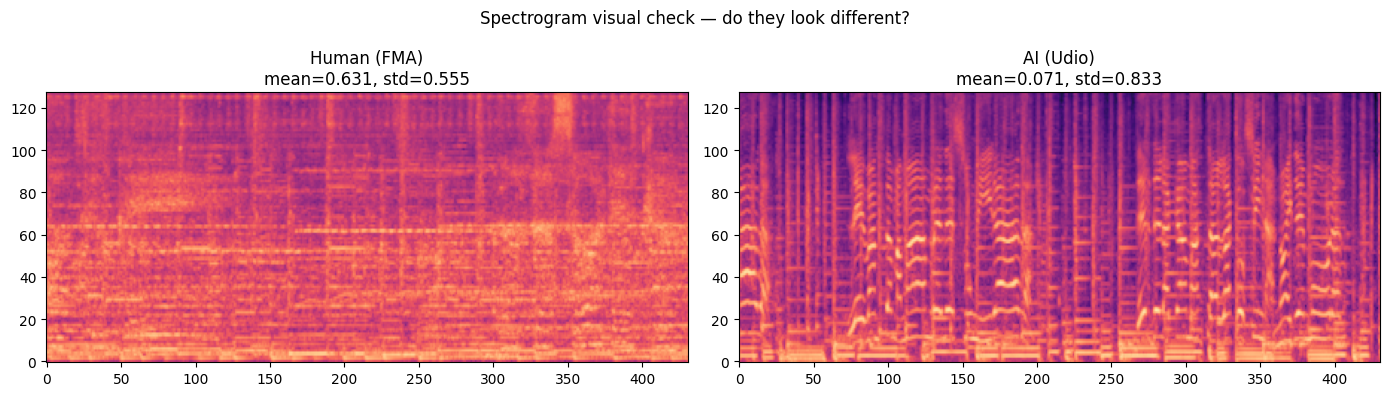

Saved → debug_spectrograms.png


In [18]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

# Load 500 train spectrograms and their labels
train_manifest = manifest[manifest["split"] == "train"].sample(
    500, random_state=42
).reset_index(drop=True)

print("Loading 500 spectrograms...")
X_train = np.stack([
    np.load(row["npy_path"]).flatten()
    for _, row in train_manifest.iterrows()
])
y_train = (train_manifest["label"] == "ai").astype(int).values

# Load 200 val spectrograms
val_manifest = manifest[manifest["split"] == "val"].sample(
    200, random_state=42
).reset_index(drop=True)

X_val = np.stack([
    np.load(row["npy_path"]).flatten()
    for _, row in val_manifest.iterrows()
])
y_val = (val_manifest["label"] == "ai").astype(int).values

print(f"X_train shape: {X_train.shape}")
print(f"y_train distribution: human={( y_train==0).sum()}, ai={(y_train==1).sum()}")

# Reduce dimensions first
from sklearn.decomposition import PCA
pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_val_pca   = pca.transform(X_val)
print(f"PCA variance explained: {pca.explained_variance_ratio_.sum():.3f}")

# Fit logistic regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_pca, y_train)

train_probs = lr.predict_proba(X_train_pca)[:, 1]
val_probs   = lr.predict_proba(X_val_pca)[:, 1]

print(f"\nLogistic Regression on spectrograms:")
print(f"  Train AUROC: {roc_auc_score(y_train, train_probs):.4f}")
print(f"  Val   AUROC: {roc_auc_score(y_val,   val_probs):.4f}")

# Also check raw spectrogram statistics
print(f"\nRaw spectrogram stats:")
print(f"  Human mean : {X_train[y_train==0].mean():.4f}")
print(f"  AI mean    : {X_train[y_train==1].mean():.4f}")
print(f"  Human std  : {X_train[y_train==0].std():.4f}")
print(f"  AI std     : {X_train[y_train==1].std():.4f}")

# Visualize one human and one AI spectrogram side by side
import matplotlib.pyplot as plt

human_idx = np.where(y_train == 0)[0][0]
ai_idx    = np.where(y_train == 1)[0][0]

human_spec = X_train[human_idx].reshape(128, -1)
ai_spec    = X_train[ai_idx].reshape(128, -1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(human_spec, aspect="auto", origin="lower",
               cmap="magma", vmin=-3, vmax=3)
axes[0].set_title(f"Human (FMA)\nmean={human_spec.mean():.3f}, "
                  f"std={human_spec.std():.3f}")
axes[1].imshow(ai_spec, aspect="auto", origin="lower",
               cmap="magma", vmin=-3, vmax=3)
axes[1].set_title(f"AI ({train_manifest.iloc[ai_idx]['source_name']})\n"
                  f"mean={ai_spec.mean():.3f}, std={ai_spec.std():.3f}")
plt.suptitle("Spectrogram visual check — do they look different?")
plt.tight_layout()
plt.savefig("debug_spectrograms.png", dpi=150)
plt.show()
print("Saved → debug_spectrograms.png")

In [19]:
import numpy as np
import pandas as pd
from pathlib import Path

# Check 10 human and 10 AI chunks
# Verify the file content matches what the label says
train_manifest = manifest[manifest["split"] == "train"].reset_index(drop=True)

human_samples = train_manifest[train_manifest["label"] == "human"].head(10)
ai_samples    = train_manifest[train_manifest["label"] == "ai"].head(10)

print("=== Label-to-file correspondence check ===\n")
print("Human samples:")
for _, row in human_samples.iterrows():
    spec = np.load(row["npy_path"])
    print(f"  {Path(row['npy_path']).name} | "
          f"label={row['label']} | "
          f"source={row['source_name']} | "
          f"mean={spec.mean():.4f} | "
          f"std={spec.std():.4f}")

print("\nAI samples:")
for _, row in ai_samples.iterrows():
    spec = np.load(row["npy_path"])
    print(f"  {Path(row['npy_path']).name} | "
          f"label={row['label']} | "
          f"source={row['source_name']} | "
          f"mean={spec.mean():.4f} | "
          f"std={spec.std():.4f}")

# Check: does the dataset __getitem__ return the right npy file?
print("\n=== Dataset __getitem__ correspondence check ===")
dataset = loaders["train"].dataset

print(f"\nDataset df label column unique: {dataset.df['label'].unique()}")
print(f"Dataset labels array unique   : {np.unique(dataset.labels)}")

# Check first 5 items directly
print("\nFirst 5 dataset items:")
for i in range(5):
    spec_tensor, label_tensor, meta = dataset[i]
    npy_path = dataset.df.iloc[i]["npy_path"]
    spec_from_disk = np.load(npy_path)

    tensors_match = np.allclose(
        spec_tensor.squeeze().numpy(),
        spec_from_disk, atol=1e-5
    )
    print(f"  idx={i} | label={label_tensor.item()} | "
          f"source={meta['source_name']} | "
          f"spec_mean={spec_tensor.mean():.4f} | "
          f"tensor_matches_disk={tensors_match}")

# Final check — does dataset index align with manifest?
print(f"\nManifest train rows  : {len(train_manifest)}")
print(f"Dataset df rows      : {len(dataset.df)}")
print(f"Manifest first path  : {train_manifest.iloc[0]['npy_path']}")
print(f"Dataset df first path: {dataset.df.iloc[0]['npy_path']}")
print(f"Paths match          : "
      f"{train_manifest.iloc[0]['npy_path'] == dataset.df.iloc[0]['npy_path']}")

=== Label-to-file correspondence check ===

Human samples:
  chunk_000000.npy | label=human | source=FMA | mean=0.3542 | std=0.8116
  chunk_000001.npy | label=human | source=FMA | mean=0.1561 | std=0.8771
  chunk_000002.npy | label=human | source=FMA | mean=0.2118 | std=0.9627
  chunk_000003.npy | label=human | source=FMA | mean=0.2732 | std=0.8288
  chunk_000004.npy | label=human | source=FMA | mean=0.2277 | std=0.8278
  chunk_000005.npy | label=human | source=FMA | mean=0.2915 | std=0.8167
  chunk_000006.npy | label=human | source=FMA | mean=-0.1033 | std=1.0140
  chunk_000007.npy | label=human | source=FMA | mean=0.0915 | std=1.0888
  chunk_000008.npy | label=human | source=FMA | mean=0.0212 | std=0.9430
  chunk_000009.npy | label=human | source=FMA | mean=0.3216 | std=0.8226

AI samples:
  chunk_000012.npy | label=ai | source=Udio | mean=0.2168 | std=0.8274
  chunk_000013.npy | label=ai | source=Udio | mean=0.2424 | std=0.7931
  chunk_000028.npy | label=ai | source=Udio | mean=-1.1

In [ ]:
from train import train, load_checkpoint
from evaluate import evaluate, save_evaluation_results, plot_training_history

RUN_NAME = f"{config.MODEL_TYPE}_{config.SPLIT_STRATEGY}"

# ── Train ─────────────────────────────────────────────────────────────────────
history_df = train(
    model    = model,
    loaders  = loaders,
    config   = config,
    device   = device,
    manifest = manifest,   # ← new required argument
    run_name = RUN_NAME,
)

# ── Plot training curves ──────────────────────────────────────────────────────
plot_training_history(
    history_df,
    output_path = config.LOGS_DIR / f"{RUN_NAME}_curves.png",
)

# ── Load best checkpoint and evaluate on test set ────────────────────────────
load_checkpoint(model, config.CHECKPOINT_DIR / f"{RUN_NAME}_best.pt", device)

test_results = evaluate(
    model      = model,
    loader     = loaders["test"],
    device     = device,
    split_name = "test",
)

save_evaluation_results(
    results    = test_results,
    output_dir = config.LOGS_DIR,
    run_name   = RUN_NAME,
    split_name = "test",
)

11:48:46 | INFO | 
11:48:46 | INFO | Training start — run='cnn_random'
11:48:46 | INFO |   Model     : cnn
11:48:46 | INFO |   Device    : mps
11:48:46 | INFO |   Epochs    : 50
11:48:46 | INFO |   Batch     : 64
11:48:46 | INFO |   LR        : 0.001
11:48:46 | INFO |   AMP       : False
11:48:46 | INFO |   Early stop: patience=15
11:48:46 | INFO | =======================================================

11:49:22 | INFO | Epoch 001/50 [35.4s | lr=1.00e-03]
11:49:22 | INFO |   TRAIN | chunk — acc=0.5069 auroc=0.5021 auprc=0.4933 | track — acc=0.2403 auroc=0.3535 auprc=0.7344
11:49:22 | INFO |   VAL   | chunk — acc=0.4394 auroc=0.4306 auprc=0.4933 | track — acc=0.2271 auroc=0.4064 auprc=0.7078
11:49:22 | INFO | Checkpoint saved → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/checkpoints/cnn_random_best.pt
11:49:22 | INFO |   ↑ New best val AUPRC: 0.4933
11:49:22 | INFO | Checkpoint saved → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/checkpoints/cnn_random_

KeyboardInterrupt: 

In [14]:
import torch
import numpy as np

model.eval()
all_probs  = []
all_labels = []

with torch.no_grad():
    for batch_inputs, batch_labels, batch_metas in loaders["train"]:
        labels_np    = batch_labels.numpy().tolist()
        batch_inputs = batch_inputs.to(device)
        logits = model(batch_inputs)
        probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        all_probs.extend(probs.tolist())
        all_labels.extend(labels_np)
        if len(all_probs) >= 1000:
            break

probs_arr  = np.array(all_probs)
labels_arr = np.array(all_labels)

print(f"=== Training set probability distribution (1000 samples) ===")
print(f"prob(AI) mean   : {probs_arr.mean():.4f}")
print(f"prob(AI) std    : {probs_arr.std():.4f}")
print(f"prob(AI) min    : {probs_arr.min():.4f}")
print(f"prob(AI) max    : {probs_arr.max():.4f}")
print(f"prob(AI) median : {np.median(probs_arr):.4f}")
print(f"Fraction > 0.5  : {(probs_arr > 0.5).mean():.4f}")
print(f"Fraction > 0.3  : {(probs_arr > 0.3).mean():.4f}")
print(f"Fraction > 0.1  : {(probs_arr > 0.1).mean():.4f}")

print(f"\nMean prob for true human (0): "
      f"{probs_arr[labels_arr==0].mean():.4f}")
print(f"Mean prob for true AI    (1): "
      f"{probs_arr[labels_arr==1].mean():.4f}")
print(f"Separation                  : "
      f"{probs_arr[labels_arr==1].mean() - probs_arr[labels_arr==0].mean():.4f}")

# Check raw logits
with torch.no_grad():
    batch_inputs, batch_labels, _ = next(iter(loaders["train"]))
    logits = model(batch_inputs.to(device))
    
print(f"\n=== Raw logits (first 5) ===")
for i in range(5):
    print(f"  label={batch_labels[i].item()} | "
          f"logit[0]={logits[i,0].item():.4f} | "
          f"logit[1]={logits[i,1].item():.4f} | "
          f"prob(AI)={torch.softmax(logits[i], dim=0)[1].item():.4f}")

=== Training set probability distribution (1000 samples) ===
prob(AI) mean   : 0.0066
prob(AI) std    : 0.0013
prob(AI) min    : 0.0040
prob(AI) max    : 0.0140
prob(AI) median : 0.0063
Fraction > 0.5  : 0.0000
Fraction > 0.3  : 0.0000
Fraction > 0.1  : 0.0000

Mean prob for true human (0): 0.0066
Mean prob for true AI    (1): 0.0066
Separation                  : -0.0000

=== Raw logits (first 5) ===
  label=1 | logit[0]=2.5964 | logit[1]=-2.5963 | prob(AI)=0.0055
  label=1 | logit[0]=2.4802 | logit[1]=-2.4800 | prob(AI)=0.0070
  label=1 | logit[0]=2.5416 | logit[1]=-2.5415 | prob(AI)=0.0062
  label=1 | logit[0]=2.6188 | logit[1]=-2.6186 | prob(AI)=0.0053
  label=1 | logit[0]=2.6418 | logit[1]=-2.6417 | prob(AI)=0.0050


In [13]:
# =============================================================================
# train.py
# =============================================================================
# Training loop with:
#   - Mixed precision (autocast) where available
#   - LR scheduler (ReduceLROnPlateau on val AUPRC)
#   - Early stopping on val AUPRC
#   - Checkpoint saving (best model + last model)
#   - Per-epoch logging of loss, accuracy, AUROC, AUPRC
#     at both chunk level and track level
#   - Full training history returned as DataFrame for plotting
# =============================================================================

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import pandas as pd
from pathlib import Path
import logging
import time
import json

log = logging.getLogger(__name__)


# ── Metric helpers (imported from evaluate.py at call time) ───────────────────
# Defined here as thin wrappers to avoid circular imports


def _compute_metrics(
    all_labels: np.ndarray,
    all_probs: np.ndarray,
    all_track_ids: np.ndarray,
    all_sources: list[str],
    threshold: float = 0.5,
) -> dict:
    """
    Compute chunk-level and track-level metrics.
    Imported lazily to avoid circular import with evaluate.py.
    """
    from evaluate import compute_chunk_metrics, compute_track_metrics

    chunk_metrics = compute_chunk_metrics(all_labels, all_probs, threshold)
    track_metrics = compute_track_metrics(
        all_labels, all_probs, all_track_ids, threshold
    )
    return {"chunk": chunk_metrics, "track": track_metrics}


# ── One epoch ─────────────────────────────────────────────────────────────────


def _run_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    is_train,
    use_amp,
    scaler,
):
    model.train(is_train)
    total_loss = 0.0
    all_labels = []
    all_probs = []
    all_track_ids = []
    all_sources = []

    context = torch.enable_grad() if is_train else torch.no_grad()

    with context:
        for batch_inputs, batch_labels, batch_metas in loader:
            # ── Collect labels BEFORE device move ─────────────────────────
            labels_np = batch_labels.numpy().tolist()
            track_ids_np = [m["track_id"] for m in batch_metas]
            sources_np = [m["source_name"] for m in batch_metas]

            # ── Move to device ────────────────────────────────────────────
            batch_inputs = batch_inputs.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)

            # ── Zero gradients BEFORE forward ─────────────────────────────
            if is_train:
                optimizer.zero_grad(set_to_none=True)

            # ── Forward pass ──────────────────────────────────────────────
            if use_amp and scaler is not None:
                with torch.autocast(device_type=device.type):
                    logits = model(batch_inputs)
                    loss = criterion(logits, batch_labels)
            else:
                logits = model(batch_inputs)
                loss = criterion(logits, batch_labels)

            # ── Backward pass ─────────────────────────────────────────────
            if is_train:
                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

            total_loss += loss.item() * batch_inputs.size(0)

            # ── Collect outputs ───────────────────────────────────────────
            probs = torch.softmax(logits, dim=1)[:, 1].detach().cpu().numpy()
            all_probs.extend(probs.tolist())
            all_labels.extend(labels_np)
            all_track_ids.extend(track_ids_np)
            all_sources.extend(sources_np)

    avg_loss = total_loss / len(loader.dataset)
    return (
        avg_loss,
        np.array(all_labels, dtype=np.int64),
        np.array(all_probs, dtype=np.float32),
        np.array(all_track_ids, dtype=np.int64),
        all_sources,
    )


# ── Logging helpers ───────────────────────────────────────────────────────────


def _format_metrics(metrics: dict, prefix: str) -> str:
    c = metrics["chunk"]
    t = metrics["track"]
    return (
        f"{prefix} | "
        f"chunk — acc={c['accuracy']:.4f} "
        f"auroc={c['auroc']:.4f} "
        f"auprc={c['auprc']:.4f} | "
        f"track — acc={t['accuracy']:.4f} "
        f"auroc={t['auroc']:.4f} "
        f"auprc={t['auprc']:.4f}"
    )


def _epoch_row(
    epoch: int,
    split: str,
    loss: float,
    metrics: dict,
) -> dict:
    """Flatten metrics into one dict for the history DataFrame."""
    c = metrics["chunk"]
    t = metrics["track"]
    return {
        "epoch": epoch,
        "split": split,
        "loss": loss,
        "chunk_accuracy": c["accuracy"],
        "chunk_auroc": c["auroc"],
        "chunk_auprc": c["auprc"],
        "chunk_f1": c["f1"],
        "track_accuracy": t["accuracy"],
        "track_auroc": t["auroc"],
        "track_auprc": t["auprc"],
        "track_f1": t["f1"],
    }


# ── Checkpoint helpers ────────────────────────────────────────────────────────


def _save_checkpoint(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    epoch: int,
    metrics: dict,
    path: Path,
    config,
) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optim_state": optimizer.state_dict(),
            "val_auprc": metrics["chunk"]["auprc"],
            "config": {
                "model_type": config.MODEL_TYPE,
                "n_mels": config.N_MELS,
                "spec_shape": config.SPEC_SHAPE,
                "cnn_channels": config.CNN_CHANNELS,
            },
        },
        path,
    )
    log.info(f"Checkpoint saved → {path}")


def load_checkpoint(
    model: nn.Module,
    path: Path,
    device: torch.device,
    optimizer: torch.optim.Optimizer | None = None,
) -> dict:
    """
    Load a saved checkpoint into model (and optionally optimizer).
    Returns the checkpoint dict for inspection.
    """
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and "optim_state" in ckpt:
        optimizer.load_state_dict(ckpt["optim_state"])
    log.info(
        f"Loaded checkpoint from {path} "
        f"(epoch={ckpt['epoch']}, "
        f"val_auprc={ckpt['val_auprc']:.4f})"
    )
    return ckpt


# ── Main training function ────────────────────────────────────────────────────


def train(
    model: nn.Module,
    loaders: dict[str, DataLoader],
    config,
    device: torch.device,
    run_name: str = "run",
) -> pd.DataFrame:
    """
    Full training loop.

    Parameters
    ----------
    model    : instantiated model (already on device)
    loaders  : dict with keys "train", "val" (and optionally "test")
    config   : config module
    device   : torch device
    run_name : used for checkpoint filenames and log prefixes

    Returns
    -------
    history : DataFrame with one row per (epoch, split) containing
              loss and all metrics — ready for plotting
    """
    # ── Setup ─────────────────────────────────────────────────────────────
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = AdamW(
        model.parameters(),
        lr=config.LEARNING_RATE,
        weight_decay=config.WEIGHT_DECAY,
    )
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="max",  # maximise val AUPRC
        patience=config.LR_PATIENCE,
        factor=config.LR_FACTOR,
        min_lr=config.LR_MIN,
    )

    # AMP only for CUDA — MPS doesn't support it yet
    use_amp = device.type == "cuda"
    scaler = torch.cuda.amp.GradScaler() if use_amp else None

    best_val_auprc = -1.0
    epochs_no_improve = 0
    history = []

    best_ckpt_path = config.CHECKPOINT_DIR / f"{run_name}_best.pt"
    last_ckpt_path = config.CHECKPOINT_DIR / f"{run_name}_last.pt"

    log.info(f"\n{'=' * 55}")
    log.info(f"Training start — run='{run_name}'")
    log.info(f"  Model     : {config.MODEL_TYPE}")
    log.info(f"  Device    : {device}")
    log.info(f"  Epochs    : {config.NUM_EPOCHS}")
    log.info(f"  Batch     : {config.BATCH_SIZE}")
    log.info(f"  LR        : {config.LEARNING_RATE}")
    log.info(f"  AMP       : {use_amp}")
    log.info(f"  Early stop: patience={config.EARLY_STOP_PATIENCE}")
    log.info(f"{'=' * 55}\n")

    for epoch in range(1, config.NUM_EPOCHS + 1):
        t0 = time.time()

        # ── Train ─────────────────────────────────────────────────────────
        train_loss, tr_labels, tr_probs, tr_tids, tr_srcs = _run_epoch(
            model,
            loaders["train"],
            criterion,
            optimizer,
            device,
            is_train=True,
            use_amp=use_amp,
            scaler=scaler,
        )
        train_metrics = _compute_metrics(tr_labels, tr_probs, tr_tids, tr_srcs)

        # ── Validate ──────────────────────────────────────────────────────
        val_loss, val_labels, val_probs, val_tids, val_srcs = _run_epoch(
            model,
            loaders["val"],
            criterion,
            None,
            device,
            is_train=False,
            use_amp=use_amp,
            scaler=None,
        )
        val_metrics = _compute_metrics(val_labels, val_probs, val_tids, val_srcs)

        val_auprc = val_metrics["chunk"]["auprc"]
        elapsed = time.time() - t0

        # ── Scheduler step ─────────────────────────────────────────────
        scheduler.step(val_auprc)
        current_lr = optimizer.param_groups[0]["lr"]

        # ── Log ────────────────────────────────────────────────────────
        log.info(
            f"Epoch {epoch:03d}/{config.NUM_EPOCHS} "
            f"[{elapsed:.1f}s | lr={current_lr:.2e}]"
        )
        log.info(_format_metrics(train_metrics, "  TRAIN"))
        log.info(_format_metrics(val_metrics, "  VAL  "))

        # ── History ────────────────────────────────────────────────────
        history.append(_epoch_row(epoch, "train", train_loss, train_metrics))
        history.append(_epoch_row(epoch, "val", val_loss, val_metrics))

        # ── Checkpoint — best model ────────────────────────────────────
        if val_auprc > best_val_auprc:
            best_val_auprc = val_auprc
            epochs_no_improve = 0
            _save_checkpoint(
                model,
                optimizer,
                epoch,
                val_metrics,
                best_ckpt_path,
                config,
            )
            log.info(f"  ↑ New best val AUPRC: {best_val_auprc:.4f}")
        else:
            epochs_no_improve += 1
            log.info(
                f"  No improvement for "
                f"{epochs_no_improve}/{config.EARLY_STOP_PATIENCE} "
                f"epochs (best={best_val_auprc:.4f})"
            )
        # ── Checkpoint — last model ────────────────────────────────────
        _save_checkpoint(
            model,
            optimizer,
            epoch,
            val_metrics,
            last_ckpt_path,
            config,
        )

        # ── Early stopping ─────────────────────────────────────────────
        if epochs_no_improve >= config.EARLY_STOP_PATIENCE:
            log.info(
                f"\nEarly stopping triggered at epoch {epoch}. "
                f"Best val AUPRC: {best_val_auprc:.4f}"
            )
            break

    # ── Save history ───────────────────────────────────────────────────────
    history_df = pd.DataFrame(history)
    history_path = config.LOGS_DIR / f"{run_name}_history.csv"
    history_df.to_csv(history_path, index=False)
    log.info(f"\nTraining history saved → {history_path}")

    log.info(f"\n{'=' * 55}")
    log.info(f"Training complete — best val AUPRC: {best_val_auprc:.4f}")
    log.info(f"Best checkpoint  → {best_ckpt_path}")
    log.info(f"{'=' * 55}")

    return history_df


In [14]:
model = build_model(config, model_type="cnn").to(device)

# Verify starting point
model.eval()
batch_inputs, batch_labels, batch_metas = next(iter(loaders["train"]))
with torch.no_grad():
    logits = model(batch_inputs.to(device))
    probs  = torch.softmax(logits, dim=1)[:, 1]

print(f"Initial prob(AI) mean : {probs.mean().item():.4f}  (target: ~0.50)")
print(f"Initial prob(AI) std  : {probs.std().item():.4f}   (target: >0.0)")
loss = nn.CrossEntropyLoss(label_smoothing=0.1)(logits, batch_labels.to(device))
print(f"Initial loss          : {loss.item():.4f}  (target: ~0.74)")

# Train
RUN_NAME   = f"{config.MODEL_TYPE}_{config.SPLIT_STRATEGY}"
history_df = train(
    model    = model,
    loaders  = loaders,
    config   = config,
    device   = device,
    run_name = RUN_NAME,
)

11:25:08 | INFO | Building model: cnn
11:25:08 | INFO | 
11:25:08 | INFO | Model: CNNClassifier
11:25:08 | INFO |   Total parameters     : 26,650
11:25:08 | INFO |   Trainable parameters : 26,650
11:25:08 | INFO | =======================================================


Initial prob(AI) mean : 0.5363  (target: ~0.50)
Initial prob(AI) std  : 0.0004   (target: >0.0)
Initial loss          : 0.6756  (target: ~0.74)


11:25:09 | INFO | 
11:25:09 | INFO | Training start — run='cnn_random'
11:25:09 | INFO |   Model     : cnn
11:25:09 | INFO |   Device    : mps
11:25:09 | INFO |   Epochs    : 50
11:25:09 | INFO |   Batch     : 64
11:25:09 | INFO |   LR        : 0.001
11:25:09 | INFO |   AMP       : False
11:25:09 | INFO |   Early stop: patience=15
11:25:09 | INFO | =======================================================

11:25:43 | INFO | Epoch 001/50 [33.9s | lr=1.00e-03]
11:25:43 | INFO |   TRAIN | chunk — acc=0.4966 auroc=0.4998 auprc=0.5038 | track — acc=0.2413 auroc=0.4297 auprc=0.7731
11:25:43 | INFO |   VAL   | chunk — acc=0.4394 auroc=0.4075 auprc=0.4931 | track — acc=0.2271 auroc=0.3822 auprc=0.7137
11:25:43 | INFO | Checkpoint saved → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/checkpoints/cnn_random_best.pt
11:25:43 | INFO |   ↑ New best val AUPRC: 0.4931
11:25:43 | INFO | Checkpoint saved → /Users/macbookpro/Documents/DSDM/Deep Learning/Final_Project/checkpoints/cnn_random_

KeyboardInterrupt: 

In [15]:
# Check what the sampler is actually doing
import numpy as np
from collections import Counter

train_dataset = loaders["train"].dataset
print(f"Dataset label distribution:")
print(f"  human (0): {(train_dataset.labels==0).sum()}")
print(f"  ai    (1): {(train_dataset.labels==1).sum()}")
print(f"  total    : {len(train_dataset.labels)}")

# Simulate one full epoch of sampler draws
sampler = loaders["train"].sampler
print(f"\nSampler type: {type(sampler).__name__}")

if hasattr(sampler, 'weights'):
    sampled_indices = list(iter(sampler))
    sampled_labels  = train_dataset.labels[sampled_indices]
    print(f"Sampled distribution over one epoch:")
    print(f"  human (0): {(sampled_labels==0).sum()}")
    print(f"  ai    (1): {(sampled_labels==1).sum()}")
    print(f"  ratio    : {(sampled_labels==1).sum()/(sampled_labels==0).sum():.2f}")

# Check val set distribution
val_dataset = loaders["val"].dataset
print(f"\nVal label distribution:")
print(f"  human (0): {(val_dataset.labels==0).sum()}")
print(f"  ai    (1): {(val_dataset.labels==1).sum()}")
h = (val_dataset.labels==0).sum()
a = (val_dataset.labels==1).sum()
print(f"  AI fraction: {a/(h+a):.3f}")
print(f"  Random AUPRC baseline (= AI fraction): {a/(h+a):.3f}")

Dataset label distribution:
  human (0): 12055
  ai    (1): 12055
  total    : 24110

Sampler type: WeightedRandomSampler
Sampled distribution over one epoch:
  human (0): 12193
  ai    (1): 11917
  ratio    : 0.98

Val label distribution:
  human (0): 2591
  ai    (1): 3306
  AI fraction: 0.561
  Random AUPRC baseline (= AI fraction): 0.561


In [16]:
import torch
import numpy as np
from sklearn.metrics import roc_auc_score, accuracy_score

model.eval()
all_probs  = []
all_labels = []

with torch.no_grad():
    for batch_inputs, batch_labels, batch_metas in loaders["val"]:
        labels_np    = batch_labels.numpy().tolist()
        batch_inputs = batch_inputs.to(device)
        logits = model(batch_inputs)
        probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        all_probs.extend(probs.tolist())
        all_labels.extend(labels_np)

probs_arr  = np.array(all_probs)
labels_arr = np.array(all_labels)

print(f"=== Val probability distribution ===")
print(f"prob(AI) mean : {probs_arr.mean():.4f}")
print(f"prob(AI) std  : {probs_arr.std():.4f}")
print(f"prob(AI) min  : {probs_arr.min():.4f}")
print(f"prob(AI) max  : {probs_arr.max():.4f}")
print(f"prob(AI) median: {np.median(probs_arr):.4f}")
print(f"\nFraction above 0.5 threshold: {(probs_arr > 0.5).mean():.4f}")

print(f"\n=== Accuracy at different thresholds ===")
for thresh in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (probs_arr >= thresh).astype(int)
    acc   = accuracy_score(labels_arr, preds)
    n_ai  = preds.sum()
    print(f"  threshold={thresh:.1f} | acc={acc:.4f} | "
          f"predicted AI: {n_ai}/{len(preds)} ({n_ai/len(preds):.3f})")

print(f"\nAUROC: {roc_auc_score(labels_arr, probs_arr):.4f}")
print(f"\nClass distribution in val:")
print(f"  human: {(labels_arr==0).sum()}")
print(f"  AI   : {(labels_arr==1).sum()}")

=== Val probability distribution ===
prob(AI) mean : 0.0752
prob(AI) std  : 0.0002
prob(AI) min  : 0.0707
prob(AI) max  : 0.0761
prob(AI) median: 0.0752

Fraction above 0.5 threshold: 0.0000

=== Accuracy at different thresholds ===
  threshold=0.1 | acc=0.4394 | predicted AI: 0/5897 (0.000)
  threshold=0.2 | acc=0.4394 | predicted AI: 0/5897 (0.000)
  threshold=0.3 | acc=0.4394 | predicted AI: 0/5897 (0.000)
  threshold=0.4 | acc=0.4394 | predicted AI: 0/5897 (0.000)
  threshold=0.5 | acc=0.4394 | predicted AI: 0/5897 (0.000)
  threshold=0.6 | acc=0.4394 | predicted AI: 0/5897 (0.000)
  threshold=0.7 | acc=0.4394 | predicted AI: 0/5897 (0.000)

AUROC: 0.4746

Class distribution in val:
  human: 2591
  AI   : 3306


In [14]:
# Quick fix — reinitialize model with zero final bias
import torch
import torch.nn as nn

def reinitialize_model(model):
    for name, m in model.named_modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out",
                                    nonlinearity="relu")
            m.weight.data *= 0.1
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)
            # Reset running stats
            m.running_mean.zero_()
            m.running_var.fill_(1.0)
            m.num_batches_tracked.zero_()
        elif isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)

    # Zero out final linear layer for unbiased start
    linears = [m for m in model.modules() if isinstance(m, nn.Linear)]
    nn.init.zeros_(linears[-1].weight)
    nn.init.zeros_(linears[-1].bias)
    return model

model = reinitialize_model(model)
model = model.to(device)

# Verify initialization
model.eval()
batch_inputs, batch_labels, batch_metas = next(iter(loaders["train"]))
batch_inputs_gpu = batch_inputs.to(device)

with torch.no_grad():
    logits = model(batch_inputs_gpu)
    probs  = torch.softmax(logits, dim=1)[:, 1]

print(f"After reinitialization:")
print(f"  logits[:5]     : {logits[:5].cpu().tolist()}")
print(f"  prob(AI)[:5]   : {probs[:5].cpu().tolist()}")
print(f"  prob(AI) mean  : {probs.mean().item():.4f}  (target: ~0.50)")
print(f"  prob(AI) std   : {probs.std().item():.4f}   (target: >0.10)")

# Quick loss check
labels_gpu = batch_labels.to(device)
loss = nn.CrossEntropyLoss(label_smoothing=0.1)(logits, labels_gpu)
print(f"  initial loss   : {loss.item():.4f}  (target: ~0.74)")

After reinitialization:
  logits[:5]     : [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
  prob(AI)[:5]   : [0.5, 0.5, 0.5, 0.5, 0.5]
  prob(AI) mean  : 0.5000  (target: ~0.50)
  prob(AI) std   : 0.0000   (target: >0.10)
  initial loss   : 0.6931  (target: ~0.74)


In [40]:
sample_spec = np.load(manifest.iloc[0]["npy_path"])
print(f"min: {sample_spec.min():.3f}")
print(f"max: {sample_spec.max():.3f}")  
print(f"mean: {sample_spec.mean():.3f}")
print(f"std: {sample_spec.std():.3f}")

min: -1.614
max: 2.783
mean: 0.349
std: 0.814


In [42]:
import torch
import numpy as np

# Test 1: Does the Dataset __getitem__ return correct labels?
dataset = loaders["train"].dataset
print("=== Test 1: Direct dataset access ===")
errors = 0
for i in range(min(100, len(dataset))):
    _, label, meta = dataset[i]
    label_val = label.item()
    if label_val not in (0, 1):
        print(f"  BAD label at idx {i}: {label_val} | meta={meta}")
        errors += 1
print(f"Errors in first 100 samples: {errors}")

# Test 2: Does collate_fn corrupt labels?
print("\n=== Test 2: Manual collate of 10 items ===")
from dataset import _collate_fn
items = [dataset[i] for i in range(10)]
inputs, labels, metas = _collate_fn(items)
print(f"Labels: {labels.tolist()}")
print(f"All valid: {all(l in (0,1) for l in labels.tolist())}")

# Test 3: Single-worker DataLoader (eliminates multiprocessing)
print("\n=== Test 3: DataLoader with num_workers=0 ===")
from torch.utils.data import DataLoader
test_loader = DataLoader(
    dataset,
    batch_size  = 32,
    shuffle     = True,
    num_workers = 0,      # force single process
    collate_fn  = _collate_fn,
)
bad_batches = 0
for batch_idx, (inputs, labels, metas) in enumerate(test_loader):
    bad = [l for l in labels.tolist() if l not in (0, 1)]
    if bad:
        bad_batches += 1
        if bad_batches <= 3:
            print(f"  Bad batch {batch_idx}: {labels[:8].tolist()}")
    if batch_idx >= 50:
        break
print(f"Bad batches in first 50: {bad_batches}")

# Test 4: Check WeightedRandomSampler weights
print("\n=== Test 4: WeightedRandomSampler weights ===")
sampler = loaders["train"].sampler
if hasattr(sampler, 'weights'):
    w = sampler.weights.numpy()
    print(f"Sampler weights dtype : {sampler.weights.dtype}")
    print(f"Weights unique values : {np.unique(w)[:10]}")
    print(f"Weights min/max       : {w.min():.4f} / {w.max():.4f}")
    print(f"Any NaN/Inf           : {np.any(np.isnan(w)) or np.any(np.isinf(w))}")
else:
    print("No sampler or not WeightedRandomSampler")

=== Test 1: Direct dataset access ===
Errors in first 100 samples: 0

=== Test 2: Manual collate of 10 items ===
Labels: [0, 0, 1, 0, 0, 1, 0, 0, 1, 1]
All valid: True

=== Test 3: DataLoader with num_workers=0 ===
Bad batches in first 50: 0

=== Test 4: WeightedRandomSampler weights ===
Sampler weights dtype : torch.float64
Weights unique values : [1.]
Weights min/max       : 1.0000 / 1.0000
Any NaN/Inf           : False


In [43]:
print(type(batch_labels), batch_labels.dtype, batch_labels.shape)

<class 'torch.Tensor'> torch.int64 torch.Size([32])


In [44]:
import torch
import numpy as np

device = torch.device("mps")

# Simulate exactly what happens in _run_epoch
test_loader = DataLoader(
    loaders["train"].dataset,
    batch_size = 32,
    shuffle    = True,
    num_workers= 0,
    collate_fn = _collate_fn,
)

print("=== Simulating _run_epoch label collection ===")
bad_count = 0

for batch_idx, (batch_inputs, batch_labels, batch_metas) in enumerate(test_loader):
    
    # Collect BEFORE device move (our fix)
    labels_before = batch_labels.numpy().tolist()
    
    # Move to device
    batch_inputs = batch_inputs.to(device, non_blocking=True)
    batch_labels_gpu = batch_labels.to(device, non_blocking=True)
    
    # Simulate forward pass
    with torch.no_grad():
        logits = model(batch_inputs)
        loss   = torch.nn.CrossEntropyLoss()(logits, batch_labels_gpu)
    
    # Method A: collect after device move (OLD way — potentially broken)
    labels_after_gpu = batch_labels_gpu.cpu().numpy().tolist()
    
    # Method B: collect from original CPU tensor after forward (safe?)
    labels_after_cpu = batch_labels.numpy().tolist()
    
    # Method C: what we collect in _run_epoch (before device move)
    labels_collected = labels_before
    
    # Check all three
    valid_a = all(l in (0,1) for l in labels_after_gpu)
    valid_b = all(l in (0,1) for l in labels_after_cpu)
    valid_c = all(l in (0,1) for l in labels_collected)
    
    if not valid_a or not valid_b or not valid_c:
        bad_count += 1
        if bad_count <= 3:
            print(f"\nBatch {batch_idx}:")
            print(f"  Method A (after GPU move → .cpu()): valid={valid_a} | {labels_after_gpu[:5]}")
            print(f"  Method B (original CPU after fwd) : valid={valid_b} | {labels_after_cpu[:5]}")
            print(f"  Method C (before GPU move)        : valid={valid_c} | {labels_collected[:5]}")
    
    if batch_idx >= 50:
        break

if bad_count == 0:
    print("All 50 batches clean across all three methods.")
    print("\nConclusion: _run_epoch code itself is correct.")
    print("The bug must be in how _run_epoch is CALLED or how results are USED.")
else:
    print(f"\nTotal bad batches: {bad_count}")

=== Simulating _run_epoch label collection ===
All 50 batches clean across all three methods.

Conclusion: _run_epoch code itself is correct.
The bug must be in how _run_epoch is CALLED or how results are USED.


In [49]:
print("=== Current dataset sizes ===")
for split in ["train", "val", "test"]:
    split_df = manifest[manifest["split"] == split]
    print(f"\n{split}:")
    print(split_df.groupby(["label", "source_name"]).size()
          .rename("chunks").to_string())
    print(f"Total: {len(split_df)}")

print(f"\n=== Model parameters ===")
total = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total:,}")
print(f"Training samples: {len(manifest[manifest['split']=='train'])}")
print(f"Ratio (params/samples): {total / len(manifest[manifest['split']=='train']):.1f}x")

=== Current dataset sizes ===

train:
label  source_name
ai     Suno             75
       Udio           2009
human  FMA            2084
Total: 4168

val:
label  source_name
ai     Suno            28
       Udio           731
human  FMA            446
Total: 1205

test:
label  source_name
ai     Suno            27
       Udio           731
human  FMA            448
Total: 1206

=== Model parameters ===
Total parameters: 421,474
Training samples: 4168
Ratio (params/samples): 101.1x


In [13]:
import torch
import numpy as np

model.eval()

# Test 1: Does the model output vary across different inputs?
print("=== Test 1: Output variance across inputs ===")
all_logits = []
with torch.no_grad():
    for i, (inputs, labels, metas) in enumerate(loaders["train"]):
        inputs = inputs.to(device)
        logits = model(inputs)
        all_logits.append(logits.cpu().numpy())
        if i >= 10:
            break

all_logits = np.concatenate(all_logits, axis=0)
print(f"Logits shape    : {all_logits.shape}")
print(f"Logit[0] (human) — mean={all_logits[:,0].mean():.4f}, "
      f"std={all_logits[:,0].std():.6f}")
print(f"Logit[1] (AI)    — mean={all_logits[:,1].mean():.4f}, "
      f"std={all_logits[:,1].std():.6f}")
print(f"Are all outputs identical: "
      f"{np.allclose(all_logits, all_logits[0], atol=1e-4)}")

# Test 2: Does a random input produce the same output?
print("\n=== Test 2: Random vs real input ===")
real_input  = next(iter(loaders["train"]))[0][:1].to(device)
zeros_input = torch.zeros_like(real_input)
ones_input  = torch.ones_like(real_input)
rand_input  = torch.randn_like(real_input)

with torch.no_grad():
    out_real  = model(real_input).cpu().numpy()
    out_zeros = model(zeros_input).cpu().numpy()
    out_ones  = model(ones_input).cpu().numpy()
    out_rand  = model(rand_input).cpu().numpy()

print(f"Real input logits  : {out_real[0]}")
print(f"Zeros input logits : {out_zeros[0]}")
print(f"Ones input logits  : {out_ones[0]}")
print(f"Random input logits: {out_rand[0]}")

# Test 3: Check gradients after one backward pass
print("\n=== Test 3: Gradient flow ===")
model.train()
inputs, labels, metas = next(iter(loaders["train"]))

labels_np    = labels.numpy().tolist()
inputs_gpu   = inputs.to(device)
labels_gpu   = labels.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer.zero_grad()
logits = model(inputs_gpu)
loss   = criterion(logits, labels_gpu)
loss.backward()

print(f"Loss value: {loss.item():.4f}")
print(f"\nGradient norms per layer:")
for name, param in model.named_parameters():
    if param.grad is not None:
        grad_norm = param.grad.norm().item()
        print(f"  {name:45s} grad_norm={grad_norm:.6f}")
    else:
        print(f"  {name:45s} NO GRADIENT")

# Test 4: Check BatchNorm running stats
print("\n=== Test 4: BatchNorm running stats ===")
for name, module in model.named_modules():
    if isinstance(module, torch.nn.BatchNorm2d):
        print(f"  {name}:")
        print(f"    running_mean: min={module.running_mean.min():.4f}, "
              f"max={module.running_mean.max():.4f}")
        print(f"    running_var : min={module.running_var.min():.4f}, "
              f"max={module.running_var.max():.4f}")
        print(f"    weight (gamma): {module.weight.data[:4].tolist()}")
        print(f"    bias (beta)   : {module.bias.data[:4].tolist()}")

=== Test 1: Output variance across inputs ===
Logits shape    : (176, 2)
Logit[0] (human) — mean=0.4943, std=0.031072
Logit[1] (AI)    — mean=-1.8574, std=0.063161
Are all outputs identical: False

=== Test 2: Random vs real input ===
Real input logits  : [ 0.4764965 -1.8231639]
Zeros input logits : [ 0.5619377 -1.7464167]
Ones input logits  : [ 0.40366977 -1.9071438 ]
Random input logits: [ 0.4068866 -2.5214112]

=== Test 3: Gradient flow ===
Loss value: 1.5200

Gradient norms per layer:
  backbone.blocks.0.block.0.weight              grad_norm=0.061948
  backbone.blocks.0.block.1.weight              grad_norm=0.005695
  backbone.blocks.0.block.1.bias                grad_norm=0.023571
  backbone.blocks.1.block.0.weight              grad_norm=0.042185
  backbone.blocks.1.block.1.weight              grad_norm=0.005117
  backbone.blocks.1.block.1.bias                grad_norm=0.019064
  backbone.blocks.2.block.0.weight              grad_norm=0.041103
  backbone.blocks.2.block.1.weight   

In [14]:
import importlib
import config
importlib.reload(config)

print(f"N_CHUNKS_FMA  : {config.N_CHUNKS_FMA}")
print(f"N_CHUNKS_UDIO : {config.N_CHUNKS_UDIO}")
print(f"N_CHUNKS_SUNO : {config.N_CHUNKS_SUNO}")
print(f"MIN_TRACK_DUR : {config.MIN_TRACK_DURATION}")
print()

# Predict expected dataset size
import pandas as pd
meta = pd.read_csv(config.META_PATH)
usable = meta[meta["duration_sec"] >= config.MIN_TRACK_DURATION]
print("Usable tracks by source:")
print(usable.groupby("source_name").size().rename("tracks").to_string())
print()

# Rough chunk estimates (70% train split)
for src, n_chunks in [("FMA",  config.N_CHUNKS_FMA),
                       ("Udio", config.N_CHUNKS_UDIO),
                       ("Suno", config.N_CHUNKS_SUNO)]:
    n_tracks = len(usable[usable["source_name"] == src])
    total    = n_tracks * n_chunks
    train_est= int(total * config.TRAIN_RATIO)
    print(f"{src:6s}: {n_tracks} tracks × {n_chunks} chunks "
          f"= {total:,} total → ~{train_est:,} train chunks")

N_CHUNKS_FMA  : 2
N_CHUNKS_UDIO : 1
N_CHUNKS_SUNO : 1
MIN_TRACK_DUR : 17.0

Usable tracks by source:
source_name
FMA     1490
Suno     182
Udio    4872

FMA   : 1490 tracks × 2 chunks = 2,980 total → ~2,086 train chunks
Udio  : 4872 tracks × 1 chunks = 4,872 total → ~3,410 train chunks
Suno  : 182 tracks × 1 chunks = 182 total → ~127 train chunks
